In [4]:
import sys
import numpy as np
import scipy
import matplotlib.pyplot as plt
import ipykernel

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("SciPy version:", scipy.__version__)
print("DSP environment ready!")

Python version: 3.15.2 (tags/v3.15.2:5e58eaa, Oct 25 2026, 17:27:03) [MSC v.1951 64 bit (AMD64)]
NumPy version: 2.5.5
SciPy version: 1.18.1
DSP environment ready!


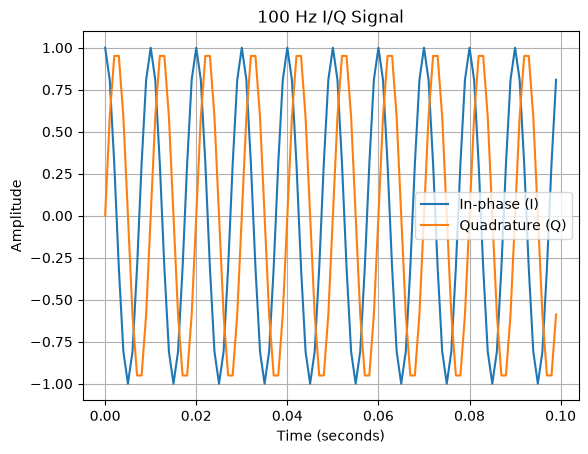

In [5]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000
f = 100
t = np.arange(0, 0.1, 1/fs)

I = np.cos(2 * np.pi * f * t)
Q = np.sin(2 * np.pi * f * t)

plt.plot(t, I, label="In-phase (I)")
plt.plot(t, Q, label="Quadrature (Q)")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("100 Hz I/Q Signal")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Sampling parameters
fs = 1000
f = 100
duration = 0.1

# Generate time samples
t = np.arange(0, duration, 1/fs)

# Generate I and Q components
I = np.cos(2 * np.pi * f * t)
Q = np.sin(2 * np.pi * f * t)

# Combine into a complex signal
x = I + 1j * Q

print("Complex signal created successfully!")
print("Number of samples:", len(x))

Complex signal created successfully!
Number of samples: 100


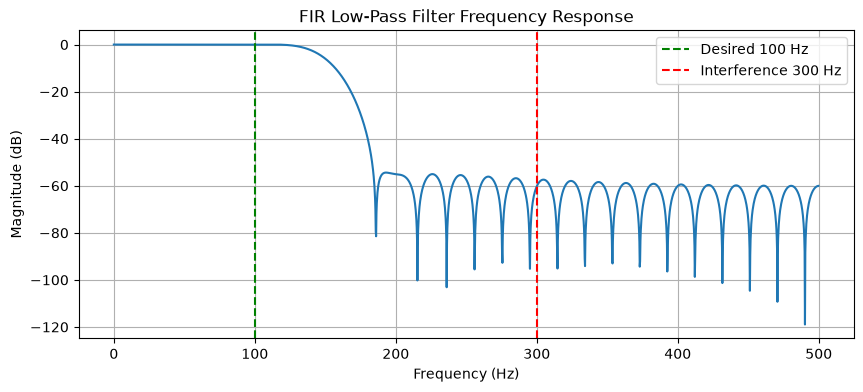

In [7]:

from scipy.signal import firwin, freqz, lfilter

# Filter parameters
fs = 1000
cutoff = 150
num_taps = 51

# Design the FIR filter
b = firwin(num_taps, cutoff, fs=fs)

# Apply the filter
filtered_signal = lfilter(b, 1.0, x)

# Calculate the frequency response
frequencies, response = freqz(b, worN=2048, fs=fs)

# Plot the filter frequency response
plt.figure(figsize=(10, 4))

plt.plot(
    frequencies,
    20 * np.log10(np.maximum(np.abs(response), 1e-12))
)

plt.axvline(100, color="green", linestyle="--", label="Desired 100 Hz")
plt.axvline(300, color="red", linestyle="--", label="Interference 300 Hz")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.title("FIR Low-Pass Filter Frequency Response")
plt.grid(True)
plt.legend()
plt.show()


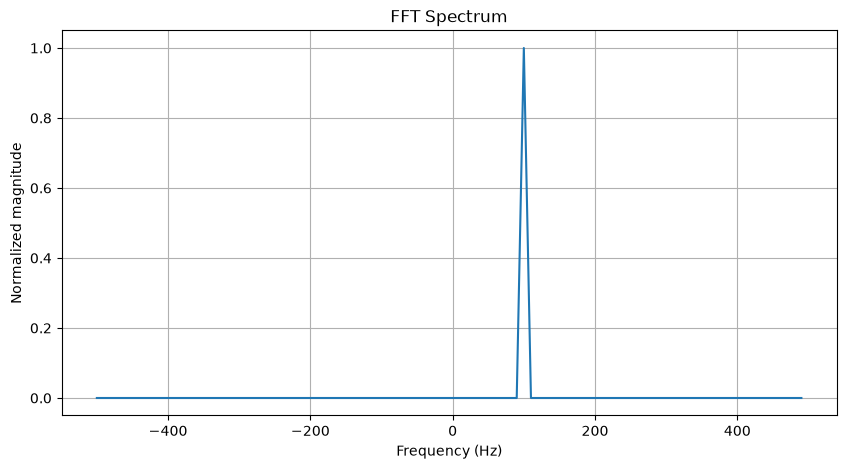

Frequency resolution: 10.0 Hz
Dominant frequency: 100.0 Hz


In [8]:
N = len(x)
X = np.fft.fft(x)

frequencies = np.fft.fftfreq(N, d=1/fs)

X_shifted = np.fft.fftshift(X)
frequencies_shifted = np.fft.fftshift(frequencies)

magnitude = np.abs(X_shifted) / N

plt.figure(figsize=(10, 5))
plt.plot(frequencies_shifted, magnitude)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Normalized magnitude")
plt.title("FFT Spectrum")
plt.grid(True)
plt.show()

peak_index = np.argmax(magnitude)
peak_frequency = frequencies_shifted[peak_index]

print("Frequency resolution:", fs/N, "Hz")
print("Dominant frequency:", peak_frequency, "Hz")

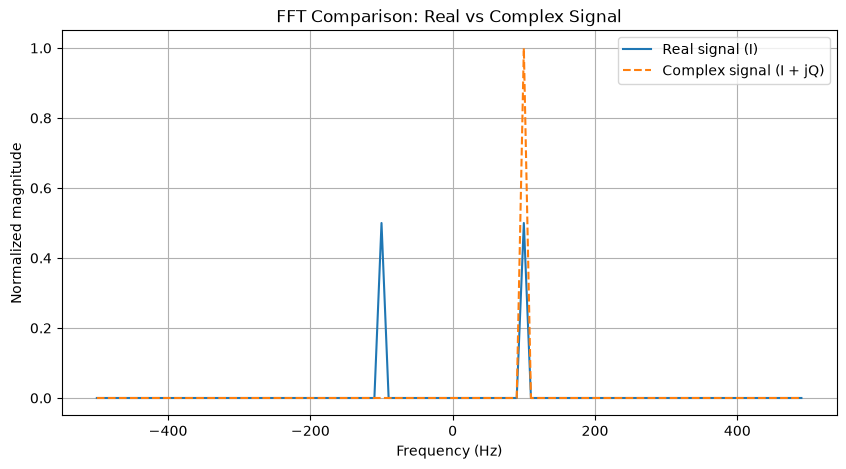

In [9]:

# FFT of the real I component
X_real = np.fft.fftshift(np.fft.fft(I))

# FFT of the complex I/Q signal
X_complex = np.fft.fftshift(np.fft.fft(x))

# Frequency axis
freq = np.fft.fftshift(np.fft.fftfreq(len(x), d=1/fs))

plt.figure(figsize=(10, 5))

plt.plot(freq, np.abs(X_real)/len(I),
         label="Real signal (I)")

plt.plot(freq, np.abs(X_complex)/len(x),
         label="Complex signal (I + jQ)",
         linestyle="--")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Normalized magnitude")
plt.title("FFT Comparison: Real vs Complex Signal")
plt.legend()
plt.grid(True)
plt.show()


In [10]:
f = 105

I = np.cos(2 * np.pi * f * t)
Q = np.sin(2 * np.pi * f * t)
x = I + 1j * Q

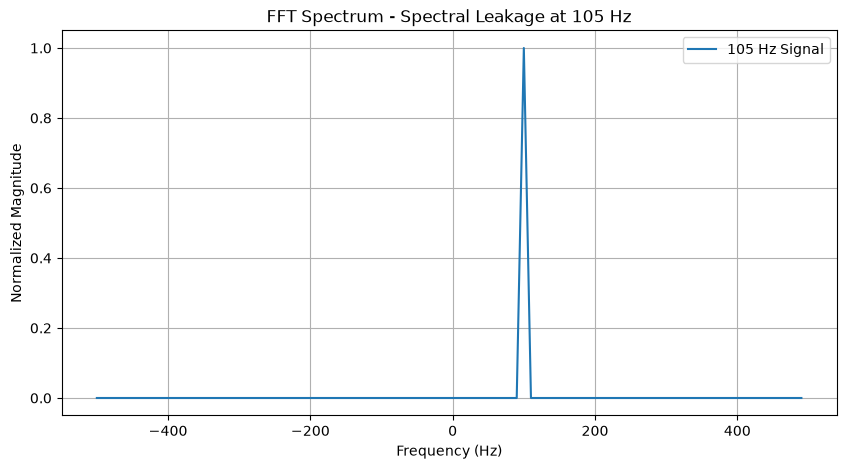

Signal frequency: 100 Hz
Sampling frequency: 1000 Hz
Number of samples: 100
Frequency resolution: 10.0 Hz
Largest FFT bin: 100.0 Hz


In [11]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Signal parameters
fs = 1000
f = 100
duration = 0.1

# 2. Generate time samples
t = np.arange(0, duration, 1/fs)

# 3. Generate complex I/Q signal
I = np.cos(2 * np.pi * f * t)
Q = np.sin(2 * np.pi * f * t)
x = I + 1j * Q

# 4. Calculate FFT
N = len(x)
X = np.fft.fft(x)

# 5. Calculate frequency bins
freq = np.fft.fftfreq(N, d=1/fs)

# 6. Shift frequency axis and FFT
X_shifted = np.fft.fftshift(X)
freq_shifted = np.fft.fftshift(freq)

# 7. Calculate normalized magnitude
magnitude = np.abs(X_shifted) / N

# 8. Plot FFT spectrum
plt.figure(figsize=(10, 5))

plt.plot(freq_shifted, magnitude,
         label="105 Hz Signal")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Normalized Magnitude")
plt.title("FFT Spectrum - Spectral Leakage at 105 Hz")
plt.legend()
plt.grid(True)
plt.show()

# 9. Display results
peak_index = np.argmax(magnitude)

print("Signal frequency:", f, "Hz")
print("Sampling frequency:", fs, "Hz")
print("Number of samples:", N)
print("Frequency resolution:", fs/N, "Hz")
print("Largest FFT bin:", freq_shifted[peak_index], "Hz")


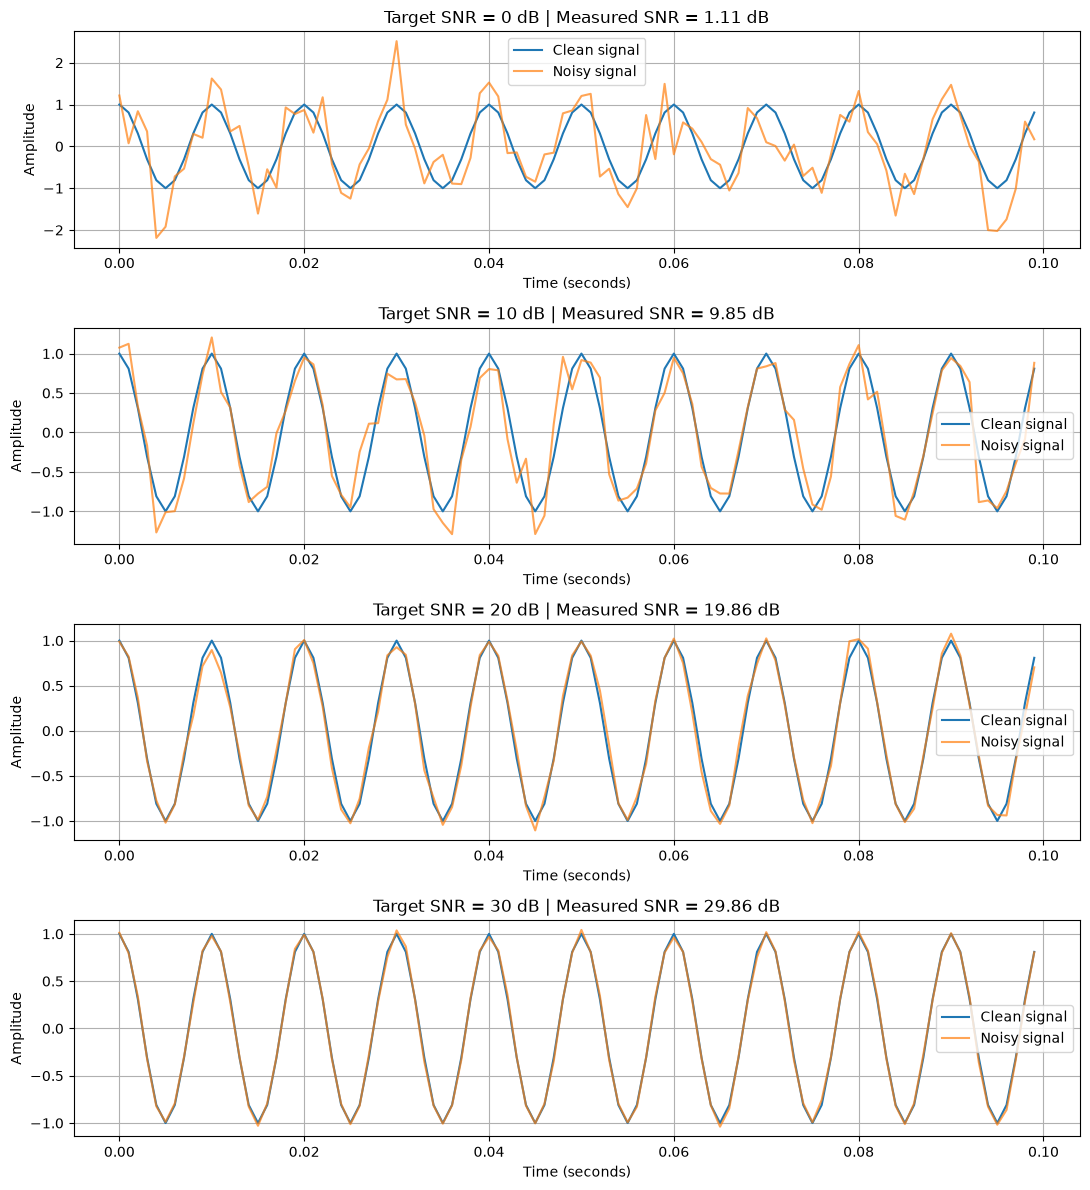

In [12]:

import numpy as np
import matplotlib.pyplot as plt

# Signal parameters
fs = 1000
f = 100
duration = 0.1

t = np.arange(0, duration, 1/fs)
N = len(t)

# Generate clean complex signal
x = np.exp(1j * 2 * np.pi * f * t)

# Calculate signal power
signal_power = np.mean(np.abs(x)**2)

# Different SNR values to test
SNR_values = [0, 10, 20, 30]

# Create 4 plots
fig, axes = plt.subplots(4, 1, figsize=(11, 12))

rng = np.random.default_rng(42)

for i, SNR_dB in enumerate(SNR_values):

    # Convert dB to linear
    SNR_linear = 10**(SNR_dB / 10)

    # Calculate noise power
    noise_power = signal_power / SNR_linear

    # Generate complex Gaussian noise
    noise = np.sqrt(noise_power / 2) * (
        rng.standard_normal(N)
        + 1j * rng.standard_normal(N)
    )

    # Add noise
    y = x + noise

    # Calculate measured SNR
    measured_SNR = 10 * np.log10(
        signal_power / np.mean(np.abs(noise)**2)
    )

    # Plot clean and noisy I components
    axes[i].plot(t, np.real(x), label="Clean signal")
    axes[i].plot(t, np.real(y), label="Noisy signal",
                 alpha=0.7)

    axes[i].set_title(
        f"Target SNR = {SNR_dB} dB | "
        f"Measured SNR = {measured_SNR:.2f} dB"
    )

    axes[i].set_xlabel("Time (seconds)")
    axes[i].set_ylabel("Amplitude")
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.show()


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


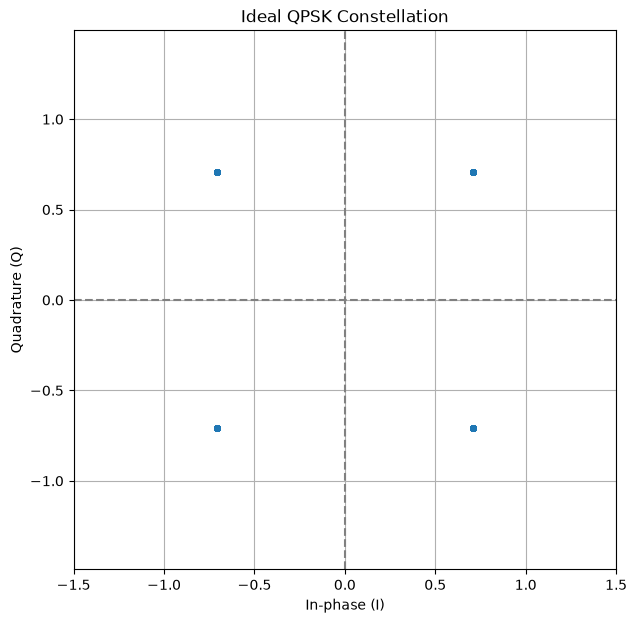

First 10 bit pairs:
[[0 1]
 [1 0]
 [0 1]
 [0 1]
 [0 0]
 [1 1]
 [1 1]
 [1 1]
 [1 0]
 [1 0]]
First 10 QPSK symbols:
[ 0.70710678-0.70710678j -0.70710678+0.70710678j  0.70710678-0.70710678j
  0.70710678-0.70710678j  0.70710678+0.70710678j -0.70710678-0.70710678j
 -0.70710678-0.70710678j -0.70710678-0.70710678j -0.70710678+0.70710678j
 -0.70710678+0.70710678j]


In [13]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Set number of symbols
N = 1000

# 2. Generate random binary data
rng = np.random.default_rng(42)
bits = rng.integers(0, 2, size=(N, 2))

# 3. Map bits to I and Q components
I = (1 - 2 * bits[:, 0]) / np.sqrt(2)
Q = (1 - 2 * bits[:, 1]) / np.sqrt(2)

# 4. Combine into complex QPSK symbols
symbols = I + 1j * Q

# 5. Plot constellation
plt.figure(figsize=(7, 7))

plt.scatter(
    symbols.real,
    symbols.imag,
    s=15,
    alpha=0.5
)

plt.xlabel("In-phase (I)")
plt.ylabel("Quadrature (Q)")
plt.title("Ideal QPSK Constellation")

plt.axhline(0, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")

plt.grid(True)
plt.axis("equal")
plt.xlim(-1.5, 1.5)
plt.ylim(-1.5, 1.5)
plt.show()

print("First 10 bit pairs:")
print(bits[:10])

print("First 10 QPSK symbols:")
print(symbols[:10])


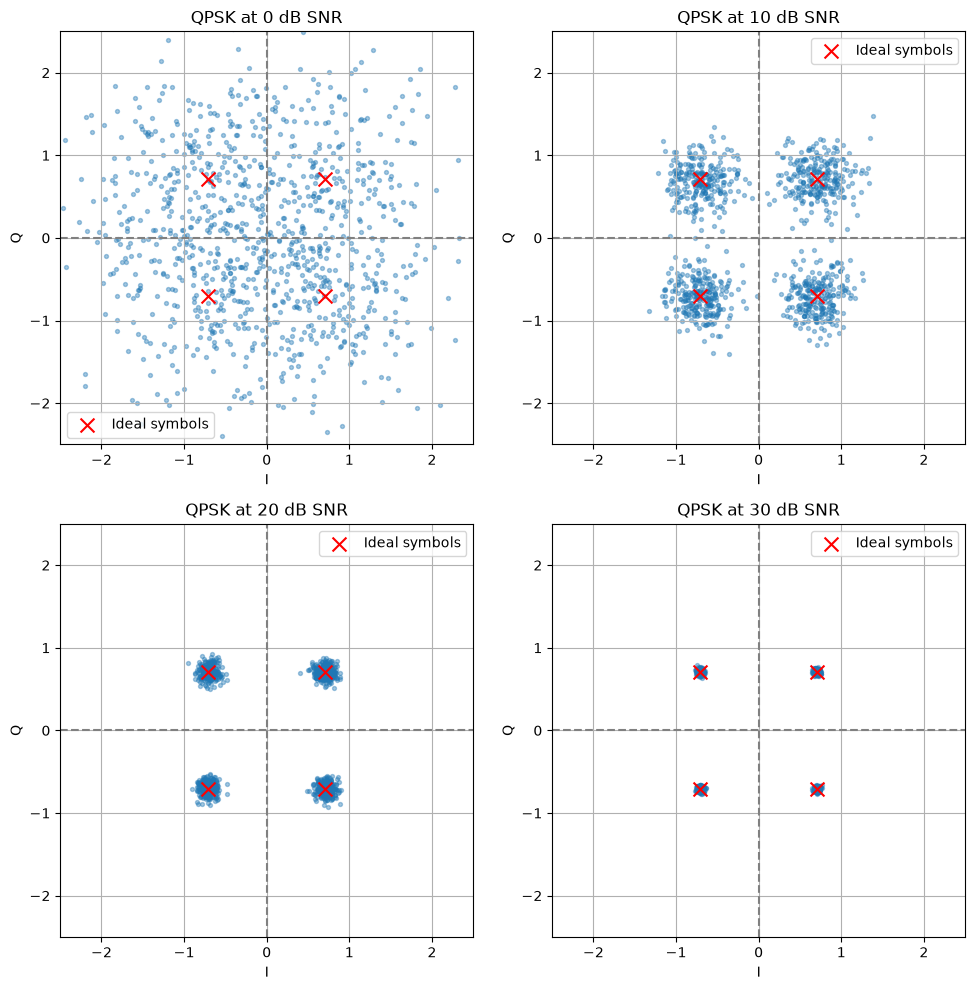

In [14]:

# SNR values to compare
SNR_values = [0, 10, 20, 30]

# Average QPSK symbol power
signal_power = np.mean(np.abs(symbols)**2)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, SNR_dB in zip(axes.flat, SNR_values):

    # Convert SNR to a linear ratio
    SNR_linear = 10**(SNR_dB / 10)

    # Calculate noise power
    noise_power = signal_power / SNR_linear

    # Generate complex AWGN
    noise = np.sqrt(noise_power / 2) * (
        rng.standard_normal(N)
        + 1j * rng.standard_normal(N)
    )

    # Add noise
    received = symbols + noise

    # Plot received symbols
    ax.scatter(
        received.real,
        received.imag,
        s=8,
        alpha=0.4
    )

    # Show ideal QPSK positions
    ideal = np.array([
        (1+1j), (-1+1j),
        (-1-1j), (1-1j)
    ]) / np.sqrt(2)

    ax.scatter(
        ideal.real,
        ideal.imag,
        marker="x",
        color="red",
        s=100,
        label="Ideal symbols"
    )

    ax.axhline(0, color="gray", linestyle="--")
    ax.axvline(0, color="gray", linestyle="--")

    ax.set_title(f"QPSK at {SNR_dB} dB SNR")
    ax.set_xlabel("I")
    ax.set_ylabel("Q")
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2.5, 2.5)
    ax.set_aspect("equal")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()


SNR:  0 dB | BER: 0.158215
SNR:  2 dB | BER: 0.105405
SNR:  4 dB | BER: 0.056225
SNR:  6 dB | BER: 0.022985
SNR:  8 dB | BER: 0.005865
SNR: 10 dB | BER: 0.000810
SNR: 12 dB | BER: 0.000030


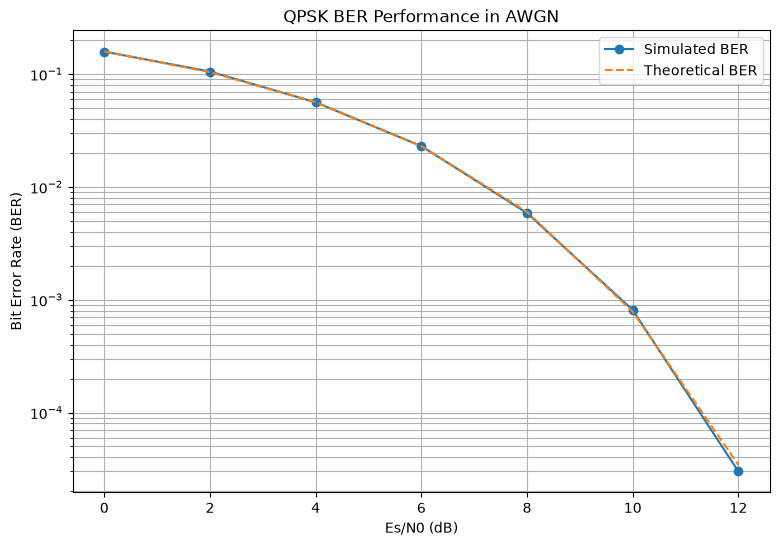

In [15]:

import numpy as np
import matplotlib.pyplot as plt

# Number of QPSK symbols
N = 100000

rng = np.random.default_rng(42)

# Generate 2 random bits per QPSK symbol
bits = rng.integers(0, 2, size=(N, 2))

# Map bits to QPSK symbols
I = (1 - 2 * bits[:, 0]) / np.sqrt(2)
Q = (1 - 2 * bits[:, 1]) / np.sqrt(2)

symbols = I + 1j * Q

# Test different SNR values (Es/N0)
SNR_values = np.arange(0, 13, 2)

BER_values = []

for SNR_dB in SNR_values:

    # Convert SNR to linear
    SNR_linear = 10**(SNR_dB / 10)

    # Calculate noise power
    noise_power = 1 / SNR_linear

    # Generate complex Gaussian noise
    noise = np.sqrt(noise_power / 2) * (
        rng.standard_normal(N)
        + 1j * rng.standard_normal(N)
    )

    # Received QPSK symbols
    received = symbols + noise

    # Detect transmitted bits
    detected_bits = np.column_stack((
        (received.real < 0).astype(int),
        (received.imag < 0).astype(int)
    ))

    # Count bit errors
    bit_errors = np.sum(bits != detected_bits)

    # Calculate BER
    BER = bit_errors / (2 * N)

    BER_values.append(BER)

    print(f"SNR: {SNR_dB:2d} dB | BER: {BER:.6f}")

# Theoretical QPSK BER in AWGN
from scipy.special import erfc

snr_linear = 10**(SNR_values / 10)
BER_theory = 0.5 * erfc(np.sqrt(snr_linear / 2))

# Plot BER comparison
plt.figure(figsize=(9, 6))

plt.semilogy(SNR_values, BER_values, "o-",
             label="Simulated BER")

plt.semilogy(SNR_values, BER_theory, "--",
             label="Theoretical BER")

plt.xlabel("Es/N0 (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("QPSK BER Performance in AWGN")
plt.grid(True, which="both")
plt.legend()
plt.show()


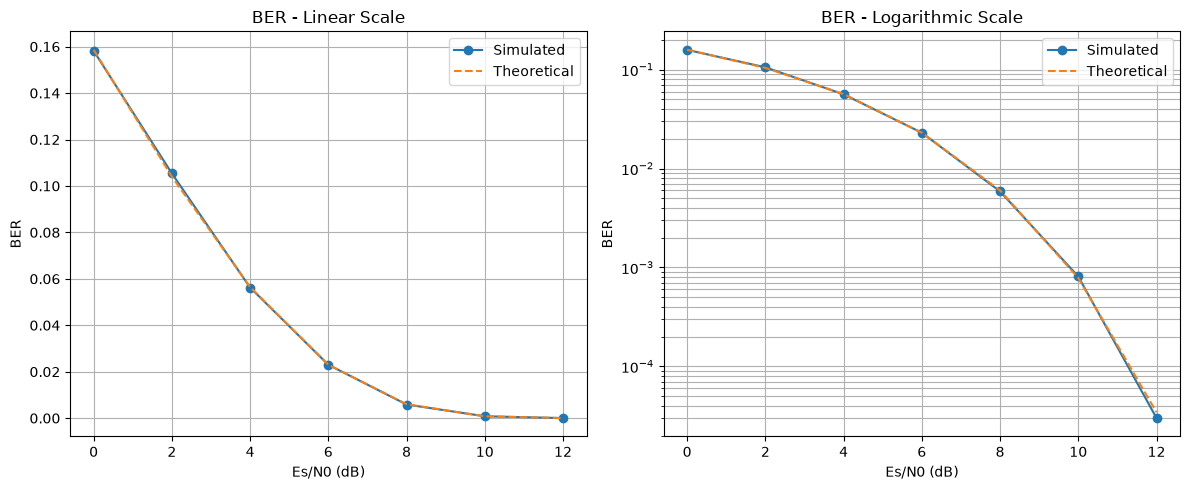

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Linear scale
axes[0].plot(SNR_values, BER_values, "o-", label="Simulated")
axes[0].plot(SNR_values, BER_theory, "--", label="Theoretical")
axes[0].set_title("BER - Linear Scale")
axes[0].set_xlabel("Es/N0 (dB)")
axes[0].set_ylabel("BER")
axes[0].grid(True)
axes[0].legend()

# Logarithmic scale
axes[1].semilogy(SNR_values, BER_values, "o-", label="Simulated")
axes[1].semilogy(SNR_values, BER_theory, "--", label="Theoretical")
axes[1].set_title("BER - Logarithmic Scale")
axes[1].set_xlabel("Es/N0 (dB)")
axes[1].set_ylabel("BER")
axes[1].grid(True, which="both")
axes[1].legend()

plt.tight_layout()
plt.show()

Signal generated successfully!
Number of samples: 100


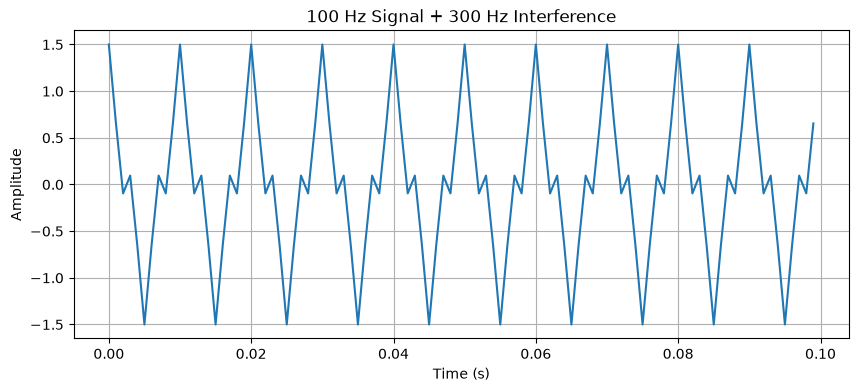

Filtering completed successfully!


In [17]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz, lfilter

# Sampling parameters
fs = 1000
duration = 0.1

# Generate time samples
t = np.arange(0, duration, 1/fs)

# Desired signal: 100 Hz
desired = np.cos(2 * np.pi * 100 * t)

# Unwanted interference: 300 Hz
interference = 0.5 * np.cos(2 * np.pi * 300 * t)

# Combine signals
x = desired + interference

print("Signal generated successfully!")
print("Number of samples:", len(x))

# Plot combined signal
plt.figure(figsize=(10, 4))
plt.plot(t, x)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("100 Hz Signal + 300 Hz Interference")
plt.grid(True)
plt.show()

# FIR filter parameters
cutoff = 150
num_taps = 51

# Design the filter
b = firwin(num_taps, cutoff, fs=fs)

# Apply filter
filtered_signal = lfilter(b, 1.0, x)

print("Filtering completed successfully!")


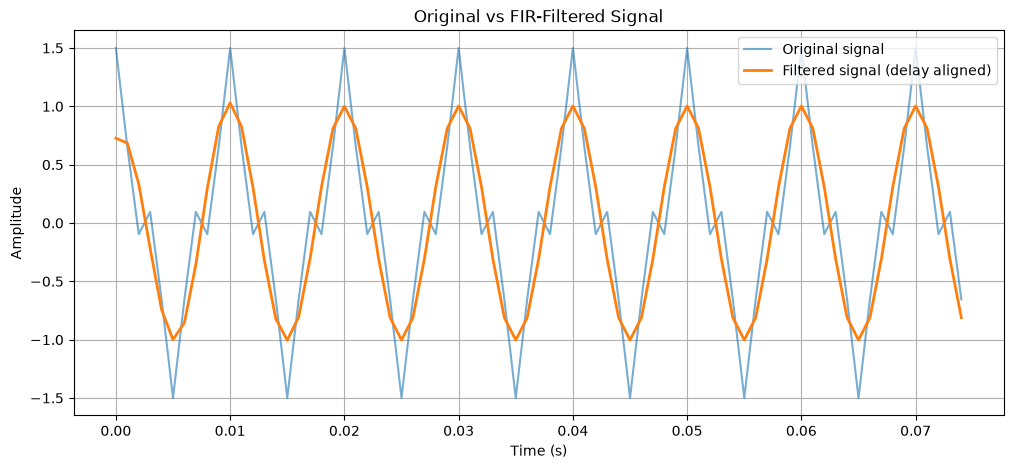

In [18]:

from scipy.signal import firwin, lfilter

# Design the low-pass FIR filter
num_taps = 51
cutoff = 150

b = firwin(num_taps, cutoff, fs=fs)

# Apply the FIR filter
filtered_signal = lfilter(b, 1.0, x)

# Compensate for the FIR group delay
delay = (num_taps - 1) // 2

# Compare the input and delay-aligned output
plt.figure(figsize=(12, 5))

plt.plot(
    t[:len(x)-delay],
    x[:len(x)-delay],
    label="Original signal",
    alpha=0.6
)

plt.plot(
    t[:len(x)-delay],
    filtered_signal[delay:],
    label="Filtered signal (delay aligned)",
    linewidth=2
)

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Original vs FIR-Filtered Signal")
plt.legend()
plt.grid(True)
plt.show()


Gain at 100 Hz: 0.02 dB
Gain at 300 Hz: -60.24 dB
Relative rejection: 60.27 dB


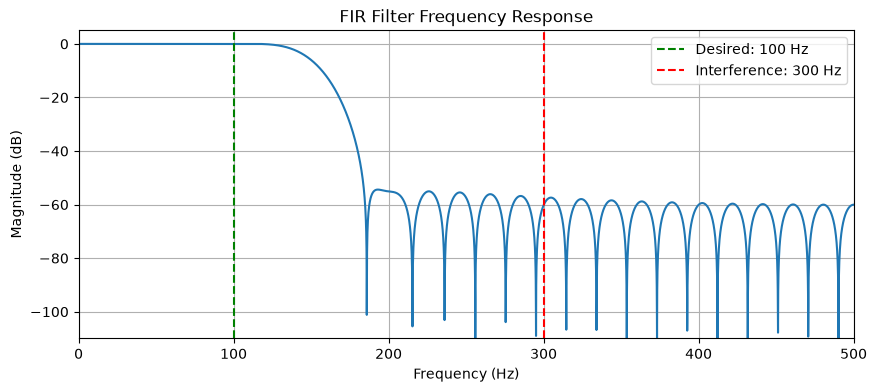

In [19]:

from scipy.signal import freqz

# Calculate frequency response of our FIR filter
frequencies, H = freqz(b, worN=8192, fs=fs)

# Convert magnitude to dB
H_dB = 20 * np.log10(
    np.maximum(np.abs(H), 1e-12)
)

# Find the closest points to 100 Hz and 300 Hz
idx_100 = np.argmin(np.abs(frequencies - 100))
idx_300 = np.argmin(np.abs(frequencies - 300))

gain_100 = H_dB[idx_100]
gain_300 = H_dB[idx_300]

print(f"Gain at 100 Hz: {gain_100:.2f} dB")
print(f"Gain at 300 Hz: {gain_300:.2f} dB")
print(f"Relative rejection: {gain_100 - gain_300:.2f} dB")

plt.figure(figsize=(10, 4))
plt.plot(frequencies, H_dB)

plt.axvline(100, color="green",
            linestyle="--", label="Desired: 100 Hz")
plt.axvline(300, color="red",
            linestyle="--", label="Interference: 300 Hz")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.title("FIR Filter Frequency Response")
plt.ylim(-110, 5)
plt.xlim(0, 500)
plt.legend()
plt.grid(True)
plt.show()


In [20]:

print(f"Gain at 100 Hz: {gain_100:.2f} dB")
print(f"Gain at 300 Hz: {gain_300:.2f} dB")
print(f"Relative rejection: {gain_100 - gain_300:.2f} dB")


Gain at 100 Hz: 0.02 dB
Gain at 300 Hz: -60.24 dB
Relative rejection: 60.27 dB


First 10 bits: [0 1 1 0 0 1 0 1 0 0]
First 10 BPSK symbols: [-1  1  1 -1 -1  1 -1  1 -1 -1]


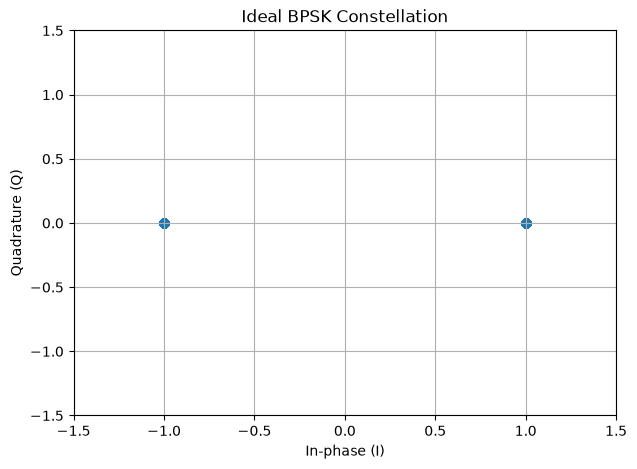

In [21]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# Generate random bits
num_symbols = 1000
bits = rng.integers(0, 2, num_symbols)

# Convert bits into BPSK symbols
bpsk = 2 * bits - 1

print("First 10 bits:", bits[:10])
print("First 10 BPSK symbols:", bpsk[:10])

# Plot constellation
plt.figure(figsize=(7, 5))
plt.scatter(
    bpsk.real,
    np.zeros(num_symbols),
    alpha=0.4
)

plt.xlabel("In-phase (I)")
plt.ylabel("Quadrature (Q)")
plt.title("Ideal BPSK Constellation")
plt.xlim(-1.5, 1.5)
plt.ylim(-1.5, 1.5)
plt.grid(True)
plt.show()


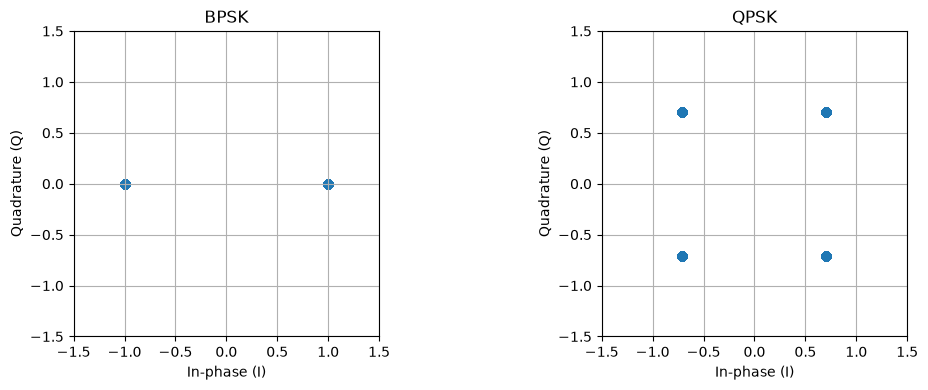

In [22]:

# Generate QPSK symbols
num_symbols = 1000

bits_qpsk = rng.integers(0, 2, (num_symbols, 2))

# Map bits to constellation coordinates
I_qpsk = 2 * bits_qpsk[:, 0] - 1
Q_qpsk = 2 * bits_qpsk[:, 1] - 1

# Normalize symbol energy to 1
qpsk = (I_qpsk + 1j * Q_qpsk) / np.sqrt(2)

# Compare BPSK and QPSK
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(bpsk.real, np.zeros(len(bpsk)))
axes[0].set_title("BPSK")

axes[1].scatter(qpsk.real, qpsk.imag)
axes[1].set_title("QPSK")

for ax in axes:
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_xlabel("In-phase (I)")
    ax.set_ylabel("Quadrature (Q)")
    ax.grid(True)
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()


In [23]:

def classify_modulation(signal):
    # Extract I and Q components
    I = np.real(signal)
    Q = np.imag(signal)

    # Calculate signal energy
    total_energy = np.mean(I**2 + Q**2)
    q_energy = np.mean(Q**2)

    # Avoid division by zero
    if total_energy == 0:
        return "Unknown", 0.0

    # Calculate classification feature
    q_ratio = q_energy / total_energy

    # Simple decision rule
    if q_ratio < 0.25:
        prediction = "BPSK"
    else:
        prediction = "QPSK"

    return prediction, q_ratio


# Test ideal BPSK
prediction_bpsk, ratio_bpsk = classify_modulation(bpsk)

# Test ideal QPSK
prediction_qpsk, ratio_qpsk = classify_modulation(qpsk)

print(f"BPSK: {prediction_bpsk}, Q-energy ratio = {ratio_bpsk:.3f}")
print(f"QPSK: {prediction_qpsk}, Q-energy ratio = {ratio_qpsk:.3f}")


BPSK: BPSK, Q-energy ratio = 0.000
QPSK: QPSK, Q-energy ratio = 0.500


SNR | BPSK Accuracy | QPSK Accuracy
 -5 |    0.0%       |  100.0%
  0 |   48.0%       |  100.0%
  5 |  100.0%       |  100.0%
 10 |  100.0%       |  100.0%
 15 |  100.0%       |  100.0%
 20 |  100.0%       |  100.0%


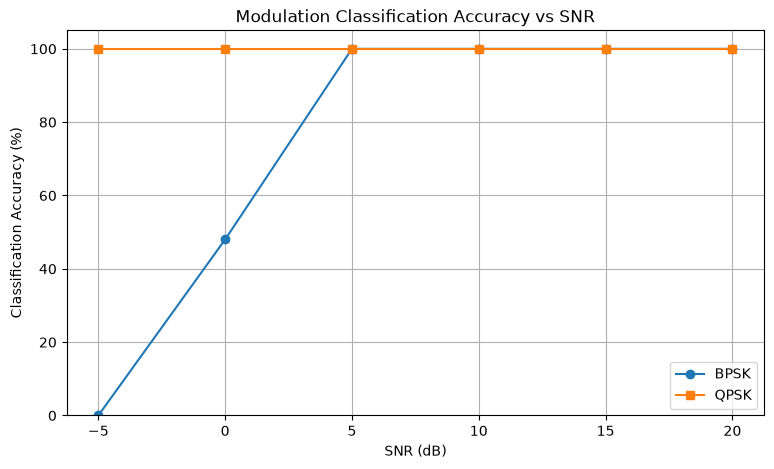

In [24]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

def add_awgn(signal, snr_db):
    signal = np.asarray(signal, dtype=complex)

    signal_power = np.mean(np.abs(signal)**2)
    snr_linear = 10**(snr_db / 10)
    noise_power = signal_power / snr_linear

    noise = (
        rng.standard_normal(len(signal))
        + 1j * rng.standard_normal(len(signal))
    ) * np.sqrt(noise_power / 2)

    return signal + noise


snr_values = [-5, 0, 5, 10, 15, 20]
num_trials = 100
num_symbols = 1000

bpsk_accuracy = []
qpsk_accuracy = []

for snr in snr_values:
    correct_bpsk = 0
    correct_qpsk = 0

    for trial in range(num_trials):
        # Generate independent BPSK symbols
        bits_bpsk = rng.integers(0, 2, num_symbols)
        signal_bpsk = 2 * bits_bpsk - 1

        # Generate independent QPSK symbols
        bits_qpsk = rng.integers(0, 2, (num_symbols, 2))
        I = 2 * bits_qpsk[:, 0] - 1
        Q = 2 * bits_qpsk[:, 1] - 1
        signal_qpsk = (I + 1j * Q) / np.sqrt(2)

        # Add complex Gaussian noise
        noisy_bpsk = add_awgn(signal_bpsk, snr)
        noisy_qpsk = add_awgn(signal_qpsk, snr)

        # Classify
        pred_bpsk, _ = classify_modulation(noisy_bpsk)
        pred_qpsk, _ = classify_modulation(noisy_qpsk)

        correct_bpsk += (pred_bpsk == "BPSK")
        correct_qpsk += (pred_qpsk == "QPSK")

    bpsk_accuracy.append(100 * correct_bpsk / num_trials)
    qpsk_accuracy.append(100 * correct_qpsk / num_trials)

print("SNR | BPSK Accuracy | QPSK Accuracy")
for snr, a, b in zip(snr_values, bpsk_accuracy, qpsk_accuracy):
    print(f"{snr:>3} | {a:>6.1f}%       | {b:>6.1f}%")


plt.figure(figsize=(9, 5))
plt.plot(snr_values, bpsk_accuracy, "o-", label="BPSK")
plt.plot(snr_values, qpsk_accuracy, "s-", label="QPSK")
plt.xlabel("SNR (dB)")
plt.ylabel("Classification Accuracy (%)")
plt.title("Modulation Classification Accuracy vs SNR")
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.show()



Confusion matrix:
[[105  95]
 [  0 200]]


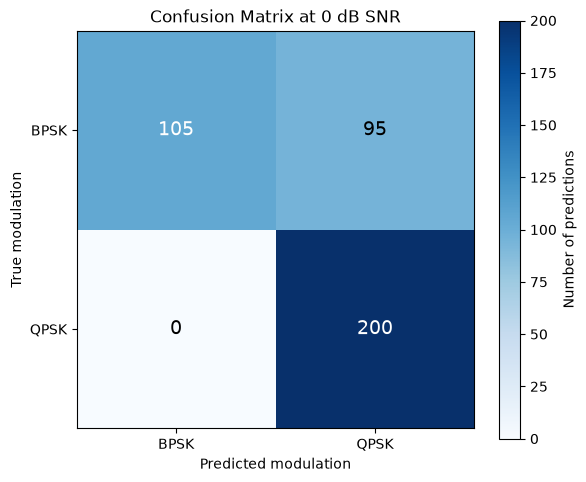

In [25]:

# Confusion matrix at 0 dB SNR

test_snr = 0
num_trials = 200
num_symbols = 1000

classes = ["BPSK", "QPSK"]
confusion = np.zeros((2, 2), dtype=int)

for true_class in range(2):
    for trial in range(num_trials):

        if true_class == 0:
            bits = rng.integers(0, 2, num_symbols)
            signal = 2 * bits - 1

        else:
            bits = rng.integers(0, 2, (num_symbols, 2))
            I = 2 * bits[:, 0] - 1
            Q = 2 * bits[:, 1] - 1
            signal = (I + 1j * Q) / np.sqrt(2)

        noisy_signal = add_awgn(signal, test_snr)
        prediction, ratio = classify_modulation(noisy_signal)

        predicted_class = classes.index(prediction)
        confusion[true_class, predicted_class] += 1

print("Confusion matrix:")
print(confusion)

plt.figure(figsize=(6, 5))
plt.imshow(confusion, cmap="Blues")

plt.xticks([0, 1], classes)
plt.yticks([0, 1], classes)

plt.xlabel("Predicted modulation")
plt.ylabel("True modulation")
plt.title("Confusion Matrix at 0 dB SNR")

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, str(confusion[i, j]),
            ha="center", va="center",
            color="white" if confusion[i, j] > 100 else "black",
            fontsize=14
        )

plt.colorbar(label="Number of predictions")
plt.tight_layout()
plt.show()


In [26]:

# Test sensitivity to carrier-phase rotation

phase_deg = 45
phase_rad = np.deg2rad(phase_deg)

# Rotate the ideal constellations
bpsk_rotated = bpsk * np.exp(1j * phase_rad)
qpsk_rotated = qpsk * np.exp(1j * phase_rad)

# Classify rotated signals
pred_bpsk, ratio_bpsk = classify_modulation(bpsk_rotated)
pred_qpsk, ratio_qpsk = classify_modulation(qpsk_rotated)

print(f"Rotated BPSK: {pred_bpsk}, Q ratio = {ratio_bpsk:.3f}")
print(f"Rotated QPSK: {pred_qpsk}, Q ratio = {ratio_qpsk:.3f}")


Rotated BPSK: QPSK, Q ratio = 0.500
Rotated QPSK: QPSK, Q ratio = 0.525


In [27]:

def classify_modulation_v2(signal):
    signal = np.asarray(signal, dtype=complex)

    # Compute average symbol power
    power = np.mean(np.abs(signal)**2)

    if power == 0:
        return "Unknown", 0.0

    # Normalized second-order moment
    m2 = np.abs(np.mean(signal**2)) / power

    # Initial decision threshold
    if m2 > 0.5:
        prediction = "BPSK"
    else:
        prediction = "QPSK"

    return prediction, m2


# Test using ideal constellations
for name, signal in [
    ("BPSK", bpsk),
    ("QPSK", qpsk),
    ("Rotated BPSK", bpsk_rotated),
    ("Rotated QPSK", qpsk_rotated)
]:
    prediction, feature = classify_modulation_v2(signal)

    print(
        f"{name:15s} -> {prediction:5s} | M2 = {feature:.3f}"
    )


BPSK            -> BPSK  | M2 = 1.000
QPSK            -> QPSK  | M2 = 0.050
Rotated BPSK    -> BPSK  | M2 = 1.000
Rotated QPSK    -> QPSK  | M2 = 0.050


SNR | Baseline | Improved
 -5 |   50.0%  |   50.0%
  0 |   51.2%  |   74.8%
  5 |   62.8%  |  100.0%
 10 |   65.5%  |  100.0%
 15 |   64.8%  |  100.0%
 20 |   66.8%  |  100.0%


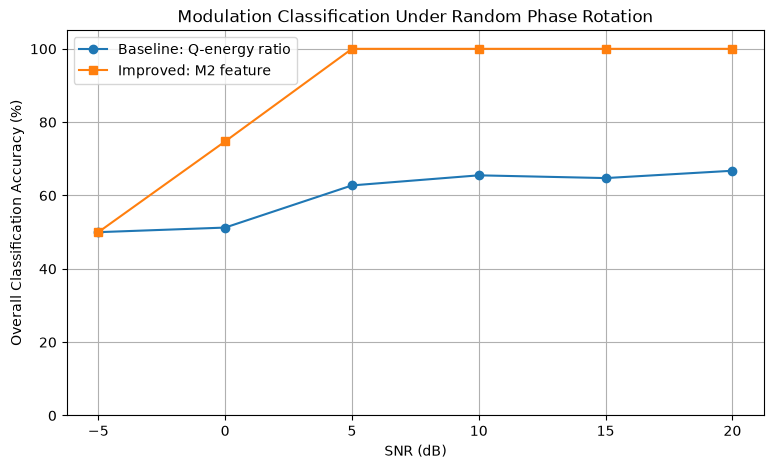

In [28]:

# Compare baseline and improved classifiers

rng = np.random.default_rng(123)

snr_values = [-5, 0, 5, 10, 15, 20]
num_trials = 200
num_symbols = 1000

baseline_accuracy = []
improved_accuracy = []

for snr in snr_values:
    baseline_correct = 0
    improved_correct = 0

    for modulation in ["BPSK", "QPSK"]:
        for trial in range(num_trials):

            if modulation == "BPSK":
                bits = rng.integers(0, 2, num_symbols)
                signal = 2 * bits - 1

            else:
                bits = rng.integers(0, 2, (num_symbols, 2))
                I = 2 * bits[:, 0] - 1
                Q = 2 * bits[:, 1] - 1
                signal = (I + 1j * Q) / np.sqrt(2)

            # Apply random carrier-phase rotation
            phase = rng.uniform(0, 2*np.pi)
            rotated = signal * np.exp(1j * phase)

            # Add AWGN
            noisy = add_awgn(rotated, snr)

            # Test both classifiers on identical data
            pred_old, _ = classify_modulation(noisy)
            pred_new, _ = classify_modulation_v2(noisy)

            baseline_correct += (pred_old == modulation)
            improved_correct += (pred_new == modulation)

    total = 2 * num_trials

    baseline_accuracy.append(
        100 * baseline_correct / total
    )

    improved_accuracy.append(
        100 * improved_correct / total
    )

# Display results
print("SNR | Baseline | Improved")
for snr, old, new in zip(
    snr_values, baseline_accuracy, improved_accuracy
):
    print(f"{snr:>3} | {old:>6.1f}%  | {new:>6.1f}%")

# Plot
plt.figure(figsize=(9, 5))

plt.plot(
    snr_values, baseline_accuracy,
    "o-", label="Baseline: Q-energy ratio"
)

plt.plot(
    snr_values, improved_accuracy,
    "s-", label="Improved: M2 feature"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Overall Classification Accuracy (%)")
plt.title("Modulation Classification Under Random Phase Rotation")
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.show()


Baseline confusion matrix:
[[ 12 188]
 [  0 200]]

Improved confusion matrix:
[[117  83]
 [  0 200]]


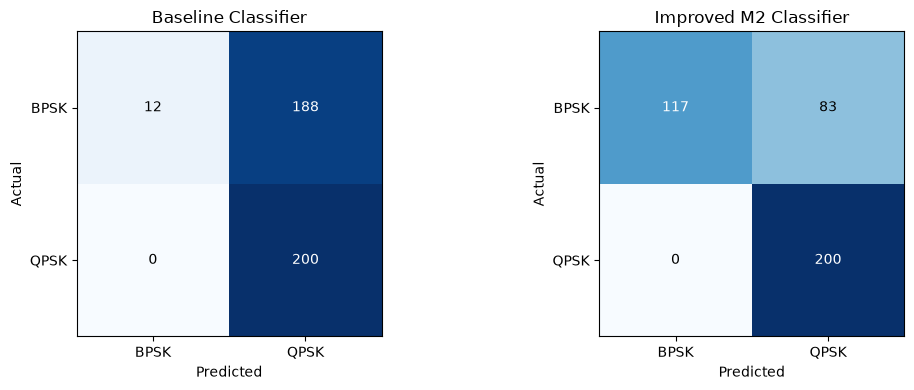

In [29]:

# Session 11 — Final classifier comparison

snr_test = 0
num_trials = 200
num_symbols = 1000

labels = ["BPSK", "QPSK"]

cm_baseline = np.zeros((2, 2), dtype=int)
cm_improved = np.zeros((2, 2), dtype=int)

for true_idx, modulation in enumerate(labels):
    for _ in range(num_trials):

        if modulation == "BPSK":
            bits = rng.integers(0, 2, num_symbols)
            signal = 2 * bits - 1
        else:
            bits = rng.integers(0, 2, (num_symbols, 2))
            I = 2 * bits[:, 0] - 1
            Q = 2 * bits[:, 1] - 1
            signal = (I + 1j * Q) / np.sqrt(2)

        # Random phase
        phase = rng.uniform(0, 2*np.pi)
        signal = signal * np.exp(1j * phase)

        # Add noise
        noisy = add_awgn(signal, snr_test)

        old_pred, _ = classify_modulation(noisy)
        new_pred, _ = classify_modulation_v2(noisy)

        cm_baseline[true_idx, labels.index(old_pred)] += 1
        cm_improved[true_idx, labels.index(new_pred)] += 1

print("Baseline confusion matrix:")
print(cm_baseline)

print("\nImproved confusion matrix:")
print(cm_improved)

# Plot both confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, cm, title in zip(
    axes,
    [cm_baseline, cm_improved],
    ["Baseline Classifier", "Improved M2 Classifier"]
):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=200)
    ax.set_xticks([0, 1], labels)
    ax.set_yticks([0, 1], labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title)

    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]),
                    ha="center", va="center",
                    color="white" if cm[i, j] > 100 else "black")

plt.tight_layout()
plt.show()
